# 03 · Introduction to Machine Learning with scikit-learn

Three small supervised-learning examples:

1. **Classification** of iris flowers with k-nearest neighbours.
2. **Classification** of students into low/high alcohol consumption with logistic regression and a random forest.
3. **Regression** of house sale prices with linear regression.

Every model is evaluated on a held-out **test set**. Scoring a model on the same rows it was trained
on overstates how well it works on new data, which is especially visible with the random forest below.

## Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

DATA_DIR = Path("..") / "data"
RANDOM_STATE = 0  # fixed seed so splits and forests are reproducible

## 1. Iris classification with k-nearest neighbours

In [2]:
iris = datasets.load_iris()
iris_features = iris.data      # 150 x 4 array of measurements
iris_target = iris.target      # 0, 1, 2 encoded species

iris_df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
iris_df["target"] = iris.target_names[iris.target]
iris_df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [4]:
# stratify keeps the same species proportions in train and test
X_train, X_test, y_train, y_test = train_test_split(
    iris_features, iris_target, test_size=0.3, stratify=iris_target, random_state=RANDOM_STATE
)

# k-NN predicts the majority class among the 3 closest training flowers
flower_classifier = KNeighborsClassifier(n_neighbors=3)
flower_classifier.fit(X_train, y_train)

print(f"Test accuracy: {flower_classifier.score(X_test, y_test):.3f}")

Test accuracy: 1.000


In [5]:
# scikit-learn expects a 2-D array: one row per flower, one column per feature
new_flowers = np.array([[5.1, 3.0, 1.1, 0.5],
                        [6.0, 2.9, 4.5, 1.1]])
predictions = flower_classifier.predict(new_flowers)

# Convert the numeric predictions back to species names
iris.target_names[predictions]

array(['setosa', 'versicolor'], dtype='<U10')

## 2. Student alcohol-consumption classification

In [6]:
student = pd.read_csv(DATA_DIR / "student.csv", sep=";")
student = student.rename(columns={"sex": "gender"})

# Weighted alcohol index: weekdays (Dalc) count 5/7, weekends (Walc) 2/7
student["alcohol_index"] = (5 * student["Dalc"] + 2 * student["Walc"]) / 7

# Alcohol consumption level: 0 = Low (index <= 2), 1 = High
student["acl"] = (student["alcohol_index"] > 2).astype(int)
student.head()

,school,gender,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,goout,Dalc,Walc,health,absences,G1,G2,G3,alcohol_index,acl
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,1,1,3,4,0,11,11,1.000000,0
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,1,1,3,2,9,11,11,1.000000,0
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,2,2,3,3,6,12,13,12,2.285714,1
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,1,1,5,0,14,14,14,1.000000,0
4,GP,F,16,U,GT3,T,3,3,other,other,...,2,1,2,5,0,11,13,13,1.285714,0


In [7]:
features = ["gender", "famsize", "age", "studytime", "famrel", "goout", "freetime", "G3"]
target = "acl"

# Encode the two text columns as 0/1 so the models can use them
student["gender"] = student["gender"].map({"F": 0, "M": 1})          # Female 0, Male 1
student["famsize"] = student["famsize"].map({"LE3": 0, "GT3": 1})    # <=3 members 0, >3 members 1

X = student[features]
y = student[target]

# Class balance: a model must beat always predicting the majority class
y.value_counts(normalize=True)

acl
0    0.744222
1    0.255778
Name: proportion, dtype: float64

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)
baseline_accuracy = y_test.value_counts(normalize=True).max()
print(f"Majority-class baseline accuracy: {baseline_accuracy:.3f}")

Majority-class baseline accuracy: 0.742


### Logistic regression

In [9]:
# Scaling puts the features on a common scale, which logistic regression needs to converge well
student_classifier_logreg = make_pipeline(StandardScaler(), LogisticRegression(C=2, max_iter=1000))
student_classifier_logreg.fit(X_train, y_train)

predictions_logreg = student_classifier_logreg.predict(X_test)

# Confusion matrix: rows = predicted, columns = actual
pd.crosstab(predictions_logreg, y_test, rownames=["predicted"], colnames=["actual"])

actual,0,1
predicted,,
0,113,28
1,8,14


In [10]:
print(f"Logistic regression test accuracy: {accuracy_score(y_test, predictions_logreg):.3f}")

Logistic regression test accuracy: 0.779


### Random forest

In [11]:
student_classifier_rf = RandomForestClassifier(random_state=RANDOM_STATE)
student_classifier_rf.fit(X_train, y_train)

predictions_rf = student_classifier_rf.predict(X_test)
pd.crosstab(predictions_rf, y_test, rownames=["predicted"], colnames=["actual"])

actual,0,1
predicted,,
0,105,27
1,16,15


In [12]:
# A forest can almost memorise its training data, which is why training accuracy is misleading
train_acc = student_classifier_rf.score(X_train, y_train)
test_acc = accuracy_score(y_test, predictions_rf)
print(f"Random forest training accuracy: {train_acc:.3f}")
print(f"Random forest test accuracy:     {test_acc:.3f}")

Random forest training accuracy: 0.996
Random forest test accuracy:     0.736


The forest is almost perfect on its training data but, on unseen students, does no better than
the majority-class baseline. This is classic overfitting, and it only becomes visible because the
model is scored on a held-out test set.

### Predicting for new students

In [13]:
def describe_prediction(model, student_features):
    """Print which alcohol-consumption group the model predicts for one student."""
    new_student = pd.DataFrame([student_features], columns=features)
    prediction = model.predict(new_student)[0]  # predict returns an array; take the single value
    group = "HIGH" if prediction == 1 else "LOW"
    print(f"The model predicts that the student belongs to the {group} alcohol consumption group")


# Female, family > 3, age 18, studytime 2, famrel 1, goout 5, freetime 5, final grade 16
describe_prediction(student_classifier_rf,
                    {"gender": 0, "famsize": 1, "age": 18, "studytime": 2,
                     "famrel": 1, "goout": 5, "freetime": 5, "G3": 16})

# Same profile but male with a final grade of 10
describe_prediction(student_classifier_rf,
                    {"gender": 1, "famsize": 1, "age": 18, "studytime": 2,
                     "famrel": 1, "goout": 5, "freetime": 5, "G3": 10})

The model predicts that the student belongs to the LOW alcohol consumption group
The model predicts that the student belongs to the HIGH alcohol consumption group


## 3. House price regression

In [14]:
housing = pd.read_csv(DATA_DIR / "house_train.csv", index_col=0)

# Age of the house at the time it was sold
housing["Age"] = housing["YrSold"] - housing["YearBuilt"]

# Keep neighbourhoods with more than 30 sales so each dummy column has enough data
counts = housing["Neighborhood"].value_counts()
more_than_30 = counts[counts > 30].index
housing = housing.loc[housing["Neighborhood"].isin(more_than_30)]
housing.shape

(1310, 81)

In [15]:
features = ["CentralAir", "LotArea", "OverallQual", "OverallCond",
            "1stFlrSF", "2ndFlrSF", "BedroomAbvGr", "Age"]
target = "SalePrice"

# One-hot encode Neighborhood; drop_first avoids a redundant (collinear) column
dummies_nb = pd.get_dummies(housing["Neighborhood"], drop_first=True, dtype=int)
housing = pd.concat([housing, dummies_nb], axis=1)
features += list(dummies_nb.columns)

# CentralAir: N -> 0, Y -> 1
housing["CentralAir"] = housing["CentralAir"].map({"N": 0, "Y": 1})

X = housing[features]
y = housing[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE)

In [16]:
# Null model: always predict the average training price. Any useful model must beat this RMSE.
y_mean = y_train.mean()
rmse_null_model = np.sqrt(mean_squared_error(y_test, np.full(len(y_test), y_mean)))
print(f"Mean training price: {y_mean:,.0f}")
print(f"Null model test RMSE: {rmse_null_model:,.0f}")

Mean training price: 181,460
Null model test RMSE: 79,586


In [17]:
regressor = LinearRegression()
regressor.fit(X_train, y_train)

y_pred = regressor.predict(X_test)
rmse_regressor = np.sqrt(mean_squared_error(y_test, y_pred))
print(f"Linear regression test RMSE: {rmse_regressor:,.0f}")

Linear regression test RMSE: 28,257


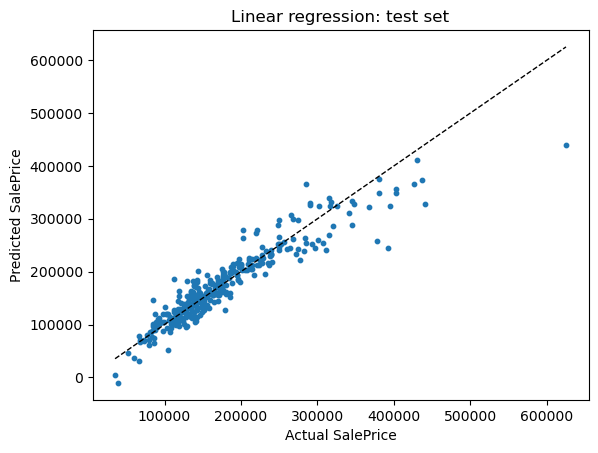

In [18]:
# Points on the dashed diagonal are perfect predictions
fig, ax = plt.subplots()
ax.scatter(y_test, y_pred, s=10)
lims = [y_test.min(), y_test.max()]
ax.plot(lims, lims, "k--", linewidth=1)
ax.set_xlabel("Actual SalePrice")
ax.set_ylabel("Predicted SalePrice")
ax.set_title("Linear regression: test set");

### Predicting the price of new houses

In [19]:
def predict_house_price(model, house, neighborhood):
    """Print the non-zero characteristics of a house and its predicted price."""
    # Start with every feature at 0, then fill in the house details and its neighbourhood dummy.
    # The reference neighbourhood (dropped by drop_first) has all dummies at 0.
    row = dict.fromkeys(features, 0)
    row.update(house)
    if neighborhood in dummies_nb.columns:
        row[neighborhood] = 1

    prediction = model.predict(pd.DataFrame([row], columns=features))[0]

    print("For a house with the following characteristics:\n")
    for feature, feature_value in row.items():
        if feature_value > 0:
            print(f"{feature}: {feature_value}")
    print(f"\nThe predicted value for the house is: {round(prediction):,}\n")


new_house = {"CentralAir": 0, "LotArea": 12000, "OverallQual": 6, "OverallCond": 6,
             "1stFlrSF": 1200, "2ndFlrSF": 500, "BedroomAbvGr": 3, "Age": 5}

predict_house_price(regressor, new_house, neighborhood="Edwards")
predict_house_price(regressor, new_house, neighborhood="Timber")

For a house with the following characteristics:

LotArea: 12000
OverallQual: 6
OverallCond: 6
1stFlrSF: 1200
2ndFlrSF: 500
BedroomAbvGr: 3
Age: 5
Edwards: 1

The predicted value for the house is: 178,809

For a house with the following characteristics:

LotArea: 12000
OverallQual: 6
OverallCond: 6
1stFlrSF: 1200
2ndFlrSF: 500
BedroomAbvGr: 3
Age: 5
Timber: 1

The predicted value for the house is: 216,362

